<a href="https://colab.research.google.com/github/khushis0503/mnist-digit-classifier/blob/main/Neural_Network_Digit_Classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Neural Network Digit Classifier — MNIST
**Mentee Activity (SWOT tracker)** — Khushi, MSc Data Science & Analytics, Jain University

Same feedforward network built in **TensorFlow/Keras** and **PyTorch**, then compared.

Architecture: `784 → 128 (ReLU) → Dropout 0.2 → 64 (ReLU) → 10 (Softmax)`


In [2]:
import time, numpy as np, matplotlib.pyplot as plt
import tensorflow as tf
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

SEED=42; np.random.seed(SEED); tf.random.set_seed(SEED); torch.manual_seed(SEED)
EPOCHS, BATCH, LR = 10, 128, 1e-3
print('TF', tf.__version__, '| Torch', torch.__version__)

TF 2.21.0 | Torch 2.14.1+cpu


## 1. Data loading & preprocessing

In [3]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
print('Train:', x_train.shape, 'Test:', x_test.shape)

# Normalise to [0,1] and flatten 28x28 -> 784
x_train = (x_train/255.0).astype('float32').reshape(-1, 784)
x_test  = (x_test/255.0).astype('float32').reshape(-1, 784)

# Hold out 10% of train for validation
val_n = 6000
x_val, y_val = x_train[-val_n:], y_train[-val_n:]
x_tr,  y_tr  = x_train[:-val_n], y_train[:-val_n]
print('Train/Val/Test:', len(x_tr), len(x_val), len(x_test))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train: (60000, 28, 28) Test: (10000, 28, 28)
Train/Val/Test: 54000 6000 10000


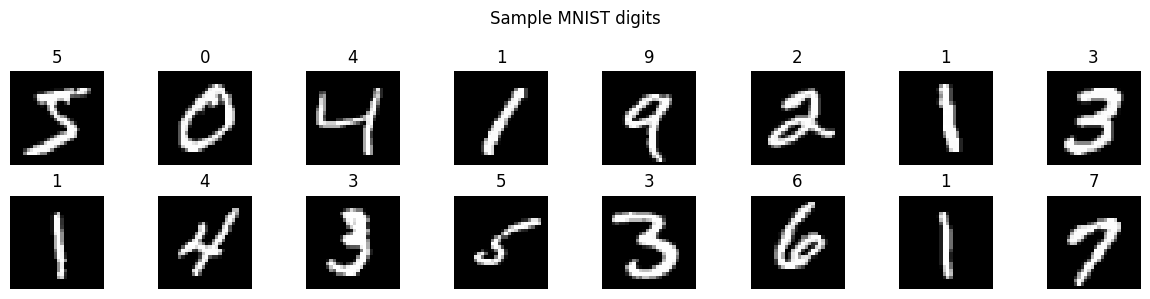

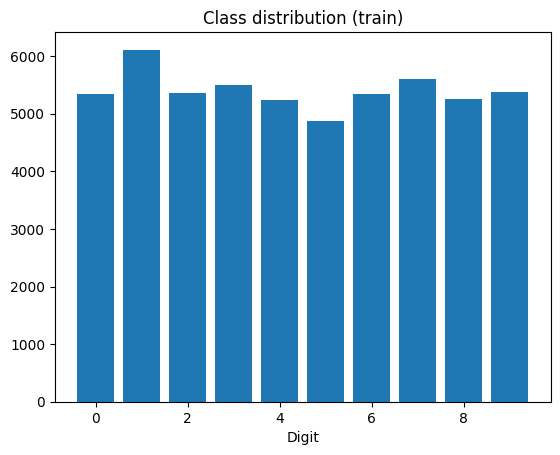

In [4]:
fig, ax = plt.subplots(2, 8, figsize=(12,3))
for i, a in enumerate(ax.flat):
    a.imshow(x_tr[i].reshape(28,28), cmap='gray'); a.set_title(y_tr[i]); a.axis('off')
plt.suptitle('Sample MNIST digits'); plt.tight_layout(); plt.show()

plt.bar(range(10), np.bincount(y_tr)); plt.title('Class distribution (train)'); plt.xlabel('Digit'); plt.show()

## 2. Model A — TensorFlow / Keras

In [5]:
tf_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])
tf_model.compile(optimizer=tf.keras.optimizers.Adam(LR),
                 loss='sparse_categorical_crossentropy', metrics=['accuracy'])
tf_model.summary()

t0 = time.time()
hist = tf_model.fit(x_tr, y_tr, validation_data=(x_val, y_val),
                    epochs=EPOCHS, batch_size=BATCH, verbose=2)
tf_time = time.time() - t0
tf_loss, tf_acc = tf_model.evaluate(x_test, y_test, verbose=0)
tf_pred = tf_model.predict(x_test, verbose=0).argmax(1)
print(f'TF test accuracy: {tf_acc:.4f} | train time: {tf_time:.1f}s')

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
422/422 - 4s - 10ms/step - accuracy: 0.8806 - loss: 0.4071 - val_accuracy: 0.9578 - val_loss: 0.1464
Epoch 2/10
422/422 - 5s - 11ms/step - accuracy: 0.9454 - loss: 0.1830 - val_accuracy: 0.9717 - val_loss: 0.1021
Epoch 3/10
422/422 - 3s - 6ms/step - accuracy: 0.9591 - loss: 0.1345 - val_accuracy: 0.9762 - val_loss: 0.0842
Epoch 4/10
422/422 - 3s - 6ms/step - accuracy: 0.9670 - loss: 0.1085 - val_accuracy: 0.9782 - val_loss: 0.0787
Epoch 5/10
422/422 - 3s - 7ms/step - accuracy: 0.9721 - loss: 0.0916 - val_accuracy: 0.9772 - val_loss: 0.0776
Epoch 6/10
422/422 - 4s - 9ms/step - accuracy: 0.9759 - loss: 0.0773 - val_accuracy: 0.9805 - val_loss: 0.0711
Epoch 7/10
422/422 - 3s - 8ms/step - accuracy: 0.9779 - loss: 0.0713 - val_accuracy: 0.9795 - val_loss: 0.0692
Epoch 8/10
422/422 - 3s - 6ms/step - accuracy: 0.9808 - loss: 0.0628 - val_accuracy: 0.9805 - val_loss: 0.0677
Epoch 9/10
422/422 - 3s - 7ms/step - accuracy: 0.9821 - loss: 0.0554 - val_accuracy: 0.9808 - val_loss: 0.0666

## 3. Model B — PyTorch

In [6]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(784,128), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(128,64), nn.ReLU(),
            nn.Linear(64,10))   # softmax is inside CrossEntropyLoss
    def forward(self, x): return self.net(x)

pt_model = MLP().to(device)
print(pt_model, '\nParams:', sum(p.numel() for p in pt_model.parameters()))

mk = lambda x,y,sh: DataLoader(TensorDataset(torch.tensor(x), torch.tensor(y).long()), batch_size=BATCH, shuffle=sh)
tr_dl, val_dl, te_dl = mk(x_tr,y_tr,True), mk(x_val,y_val,False), mk(x_test,y_test,False)
opt = torch.optim.Adam(pt_model.parameters(), lr=LR)
loss_fn = nn.CrossEntropyLoss()

def run_eval(dl):
    pt_model.eval(); correct=n=0; loss=0; preds=[]
    with torch.no_grad():
        for xb,yb in dl:
            xb,yb = xb.to(device), yb.to(device); out = pt_model(xb)
            loss += loss_fn(out,yb).item()*len(yb); p = out.argmax(1)
            correct += (p==yb).sum().item(); n += len(yb); preds.append(p.cpu())
    return loss/n, correct/n, torch.cat(preds).numpy()

pt_hist = {'loss':[], 'val_loss':[], 'accuracy':[], 'val_accuracy':[]}
t0 = time.time()
for ep in range(EPOCHS):
    pt_model.train()
    for xb,yb in tr_dl:
        xb,yb = xb.to(device), yb.to(device)
        opt.zero_grad(); l = loss_fn(pt_model(xb), yb); l.backward(); opt.step()
    trl, tra, _ = run_eval(tr_dl); vl, va, _ = run_eval(val_dl)
    for k,v in zip(pt_hist, [trl,vl,tra,va]): pt_hist[k].append(v)
    print(f'Epoch {ep+1}/{EPOCHS}  loss {trl:.4f}  acc {tra:.4f}  val_loss {vl:.4f}  val_acc {va:.4f}')
pt_time = time.time() - t0
_, pt_acc, pt_pred = run_eval(te_dl)
print(f'PyTorch test accuracy: {pt_acc:.4f} | train time: {pt_time:.1f}s')

MLP(
  (net): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=10, bias=True)
  )
) 
Params: 109386
Epoch 1/10  loss 0.2084  acc 0.9389  val_loss 0.1704  val_acc 0.9502
Epoch 2/10  loss 0.1347  acc 0.9602  val_loss 0.1154  val_acc 0.9673
Epoch 3/10  loss 0.0973  acc 0.9710  val_loss 0.0938  val_acc 0.9727
Epoch 4/10  loss 0.0757  acc 0.9769  val_loss 0.0835  val_acc 0.9753
Epoch 5/10  loss 0.0645  acc 0.9801  val_loss 0.0816  val_acc 0.9760
Epoch 6/10  loss 0.0518  acc 0.9849  val_loss 0.0738  val_acc 0.9787
Epoch 7/10  loss 0.0434  acc 0.9882  val_loss 0.0697  val_acc 0.9802
Epoch 8/10  loss 0.0375  acc 0.9886  val_loss 0.0663  val_acc 0.9800
Epoch 9/10  loss 0.0308  acc 0.9911  val_loss 0.0713  val_acc 0.9785
Epoch 10/10  loss 0.0267  acc 0.9924  val_loss 0.0628  val_acc 0.9810
PyTorch

## 4. Evaluation & comparison

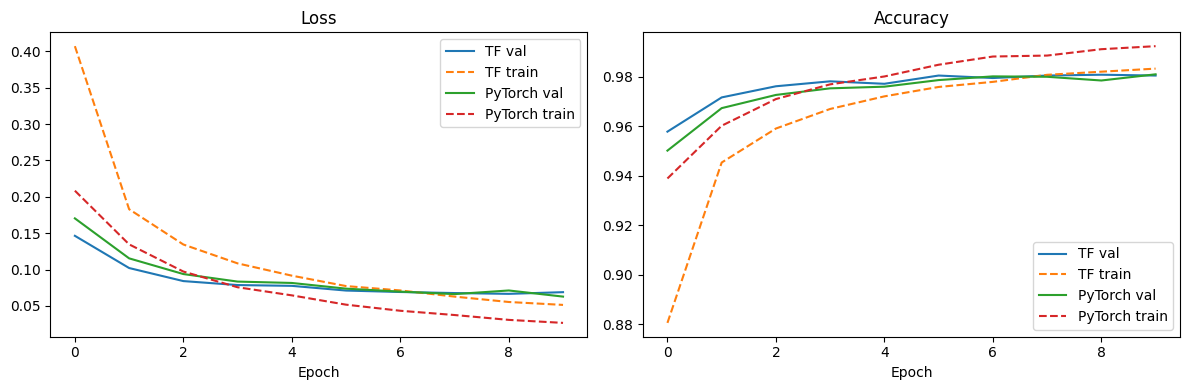

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12,4))
for name, h in [('TF', hist.history), ('PyTorch', pt_hist)]:
    ax[0].plot(h['val_loss'], label=f'{name} val'); ax[0].plot(h['loss'], '--', label=f'{name} train')
    ax[1].plot(h['val_accuracy'], label=f'{name} val'); ax[1].plot(h['accuracy'], '--', label=f'{name} train')
ax[0].set_title('Loss'); ax[1].set_title('Accuracy')
for a in ax: a.set_xlabel('Epoch'); a.legend()
plt.tight_layout(); plt.show()

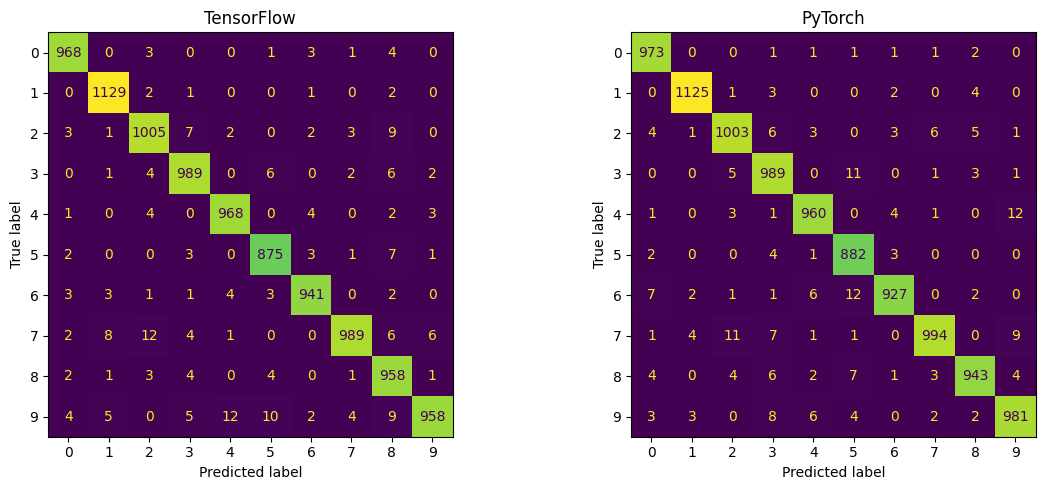

              precision    recall  f1-score   support

           0     0.9779    0.9929    0.9853       980
           1     0.9912    0.9912    0.9912      1135
           2     0.9757    0.9719    0.9738      1032
           3     0.9639    0.9792    0.9715      1010
           4     0.9796    0.9776    0.9786       982
           5     0.9608    0.9888    0.9746       892
           6     0.9851    0.9676    0.9763       958
           7     0.9861    0.9669    0.9764      1028
           8     0.9813    0.9682    0.9747       974
           9     0.9732    0.9722    0.9727      1009

    accuracy                         0.9777     10000
   macro avg     0.9775    0.9777    0.9775     10000
weighted avg     0.9778    0.9777    0.9777     10000



In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12,5))
ConfusionMatrixDisplay(confusion_matrix(y_test, tf_pred)).plot(ax=ax[0], colorbar=False); ax[0].set_title('TensorFlow')
ConfusionMatrixDisplay(confusion_matrix(y_test, pt_pred)).plot(ax=ax[1], colorbar=False); ax[1].set_title('PyTorch')
plt.tight_layout(); plt.show()
print(classification_report(y_test, pt_pred, digits=4))

In [9]:
import pandas as pd
n_params = sum(p.numel() for p in pt_model.parameters())
summary = pd.DataFrame({
    'Framework': ['TensorFlow/Keras', 'PyTorch'],
    'Test accuracy': [round(tf_acc,4), round(pt_acc,4)],
    'Train time (s)': [round(tf_time,1), round(pt_time,1)],
    'Parameters': [tf_model.count_params(), n_params]})
summary

,Framework,Test accuracy,Train time (s),Parameters
0,TensorFlow/Keras,0.9780,38.2,109386
1,PyTorch,0.9777,39.1,109386


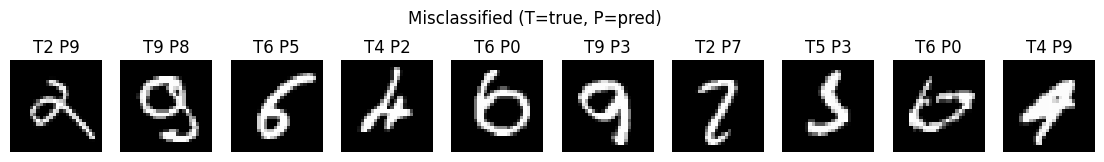

In [10]:
# Misclassified examples (PyTorch)
wrong = np.where(pt_pred != y_test)[0][:10]
fig, ax = plt.subplots(1, 10, figsize=(14,2))
for a, i in zip(ax, wrong):
    a.imshow(x_test[i].reshape(28,28), cmap='gray'); a.set_title(f'T{y_test[i]} P{pt_pred[i]}'); a.axis('off')
plt.suptitle('Misclassified (T=true, P=pred)'); plt.show()